# Soft sensor for diethylbenzene (CSTR, Aspen Dynamics history data)

Predicts the outlet mole fractions of ETBENZ and D-ETBENZ from easy-to-measure
temperatures, pressures, flows, level, and controller setpoints.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor

print("Libraries Loaded")


Libraries Loaded


## 1. Load the data

In [2]:
DATA_PATH = "/kaggle/input/datasets/voidsyntaxdev/cstr-dataset/predicted_20000_full.csv"   
DT_HOURS = 0.01
GAP_TOL = 1.5 * DT_HOURS                       

raw = pd.read_csv(DATA_PATH, skiprows=[1])   
raw.columns = [c.strip() for c in raw.columns]
df = raw.apply(pd.to_numeric, errors="coerce")
df = df.dropna(subset=["Time"]).sort_values("Time").reset_index(drop=True)
print("rows:", len(df), "| time span (h):", df["Time"].min(), "to", df["Time"].max())


rows: 20000 | time span (h): 0.0 to 199.99


## 2. Define targets and inputs

Targets are the two outlet mole fractions. Inputs are the four setpoints, which are
the variables you change in the simulation. Measured variables are the
easy-to-measure signals a plant would have.

In [3]:
TARGETS = ['STREAMS("OUTLET").In_F.z("ETBENZ")',
           'STREAMS("OUTLET").In_F.z("D-ETBENZ")']

INPUTS = ["TC.SP", "LC.SP", "FCE.SP", "FCB.SP"]

MEASURED = ['BLOCKS("B1").T', 'BLOCKS("B1").Q', 'BLOCKS("B1").level',
            'BLOCKS("B1").P',
            'STREAMS("OUTLET").In_F.T', 'STREAMS("OUTLET").In_F.P',
            'STREAMS("ETHYLENE").F', 'STREAMS("BENZENE").F',
            'STREAMS("BENZENE").T', 'STREAMS("BENZENE").P',
            'STREAMS("ETHYLENE").T', 'STREAMS("ETHYLENE").P']

missing = [c for c in TARGETS + INPUTS + MEASURED if c not in df.columns]
print("missing columns:", missing)


missing columns: []


## 3. Keep only normal operation

Remove rows where the reactor, level, or setpoints are outside the normal band.
Excursions (for example reactor temperature near 250 °C) teach the model behavior
you don't operate in, and tree models can't extrapolate from them.

In [4]:
BANDS = {'BLOCKS("B1").T': (120, 145),
         'BLOCKS("B1").level': (3, 8),
         "LC.SP": (4, 6),
         "FCE.SP": (560, 840),
         "FCB.SP": (1280, 1920),
         "TC.SP": (120, 145)}

mask = pd.Series(True, index=df.index)
for col, (lo, hi) in BANDS.items():
    mask &= df[col].between(lo, hi)
print("rows outside normal band:", int((~mask).sum()))
df = df[mask].copy()

# segment id: a new segment starts wherever the time jumps (rows were removed)
df["seg"] = (df["Time"].diff().fillna(0) > GAP_TOL).cumsum()
print("continuous segments:", df["seg"].nunique(), "| rows kept:", len(df))


rows outside normal band: 0
continuous segments: 1 | rows kept: 20000


## 4. Lag features

Past values of each measurement help because the process has dynamics. Lags are
computed **within each segment** so no feature crosses a gap.

In [5]:
LAGS = [1, 2, 5, 10, 20]    

base_cols = INPUTS + MEASURED
feat_cols = list(base_cols)
for c in base_cols:
    for L in LAGS:
        name = f"{c}__lag{L}"
        df[name] = df.groupby("seg")[c].shift(L)
        feat_cols.append(name)

data = df.dropna(subset=feat_cols + TARGETS).reset_index(drop=True)
print("rows with complete features:", len(data), "| features:", len(feat_cols))


rows with complete features: 19980 | features: 96


## 5. Time-based train/test split

Training uses the first 70% of time and testing the last 30%. Random splitting
would leak information between neighboring samples, which overstates accuracy.

In [6]:
split = int(len(data) * 0.70)
train = data.iloc[:split].copy()
test = data.iloc[split:].copy()

X_tr_all = train[feat_cols]
keep = X_tr_all.columns[X_tr_all.std() > 1e-9]
X_tr = train[keep]
X_te = test[keep]
print("train:", len(train), "| test:", len(test), "| features kept:", len(keep))
print("test segments:", sorted(test["seg"].unique()))


train: 13986 | test: 5994 | features kept: 60
test segments: [np.int64(0)]


## 6. Check whether the test data falls outside the training range

Tree models predict the nearest training value. If the test inputs fall outside
the training range, the errors will be larger for that reason, not because the
model is wrong.

In [7]:
out_frac = ((X_te < X_tr.min()) | (X_te > X_tr.max())).mean().mean()
print(f"fraction of test feature values outside training range: {out_frac:.3%}")


fraction of test feature values outside training range: 1.248%


## 7. Train and compare models

In [8]:
def metrics(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}

scaler = StandardScaler().fit(X_tr)
Xtr_s = scaler.transform(X_tr)
Xte_s = scaler.transform(X_te)

# MLP settings for each target
MLP_SETTINGS = {
    'STREAMS("OUTLET").In_F.z("ETBENZ")': {
        "hidden_layer_sizes": (32, 16), "alpha": 1e-2, "learning_rate_init": 1e-3,
    },
    'STREAMS("OUTLET").In_F.z("D-ETBENZ")': {
        "hidden_layer_sizes": (16,), "alpha": 1e-3, "learning_rate_init": 1e-3,
    },
}

rows = []
preds = {}
for tgt in TARGETS:
    y_tr = train[tgt].values
    y_te = test[tgt].values

    # baseline: always predict the training mean
    rows.append({"target": tgt, "model": "Mean (baseline)",
                 **metrics(y_te, np.full_like(y_te, y_tr.mean()))})

    s = MLP_SETTINGS[tgt]
    mlp_name = f"MLP {s['hidden_layer_sizes']}"

    candidates = {
        "Ridge": Ridge(alpha=1.0),
        "PLS (5 components)": PLSRegression(n_components=5),
        "RandomForest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                              random_state=42, n_jobs=-1),
        "SVR (RBF)": TransformedTargetRegressor(
            regressor=SVR(C=10, epsilon=0.01, gamma="scale"),
            transformer=StandardScaler()),
        mlp_name: TransformedTargetRegressor(
            regressor=MLPRegressor(hidden_layer_sizes=s["hidden_layer_sizes"],
                                   activation="relu", alpha=s["alpha"],
                                   learning_rate_init=s["learning_rate_init"],
                                   max_iter=2000, early_stopping=True,
                                   validation_fraction=0.15, n_iter_no_change=50,
                                   random_state=42),
            transformer=StandardScaler()),
        "Gradient boosting": GradientBoostingRegressor(
            n_estimators=300, learning_rate=0.05, max_depth=3,
            subsample=0.8, random_state=42),
    }
    for name, m in candidates.items():
        m.fit(Xtr_s, y_tr)
        p = np.ravel(m.predict(Xte_s))
        preds[(tgt, name)] = (m, p)
        rows.append({"target": tgt, "model": name, **metrics(y_te, p)})

results = pd.DataFrame(rows)
results

,target,model,RMSE,MAE,R2
0,"STREAMS(""OUTLET"").In_F.z(""ETBENZ"")",Mean (baseline),0.034084,0.027634,-0.000628
1,"STREAMS(""OUTLET"").In_F.z(""ETBENZ"")",Ridge,0.005570,0.003438,0.973280
2,"STREAMS(""OUTLET"").In_F.z(""ETBENZ"")",PLS (5 components),0.007936,0.005937,0.945750
3,"STREAMS(""OUTLET"").In_F.z(""ETBENZ"")",RandomForest,0.012043,0.009723,0.875075
4,"STREAMS(""OUTLET"").In_F.z(""ETBENZ"")",SVR (RBF),0.007035,0.004712,0.957372
5,"STREAMS(""OUTLET"").In_F.z(""ETBENZ"")","MLP (32, 16)",0.004900,0.003548,0.979323
6,"STREAMS(""OUTLET"").In_F.z(""ETBENZ"")",Gradient boosting,0.009718,0.007604,0.918654
7,"STREAMS(""OUTLET"").In_F.z(""D-ETBENZ"")",Mean (baseline),0.000132,0.000098,-0.048254
8,"STREAMS(""OUTLET"").In_F.z(""D-ETBENZ"")",Ridge,0.000067,0.000047,0.732672
9,"STREAMS(""OUTLET"").In_F.z(""D-ETBENZ"")",PLS (5 components),0.000086,0.000064,0.557208


## 8. Plot true vs predicted on the test period

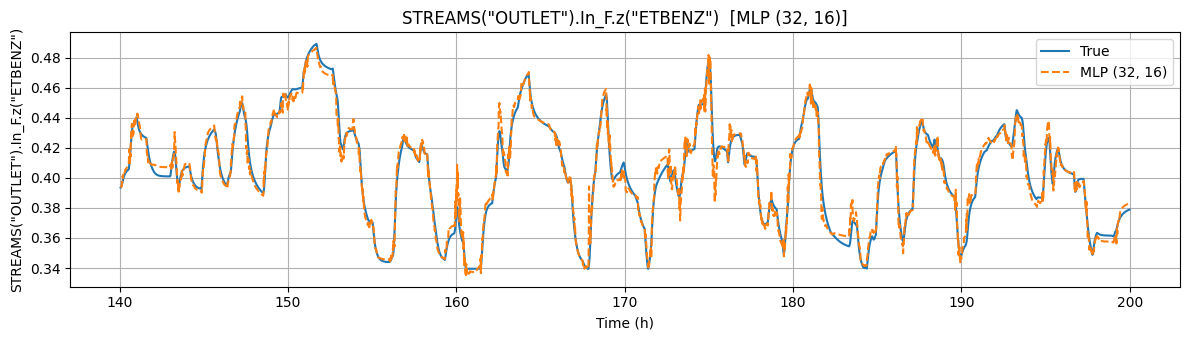

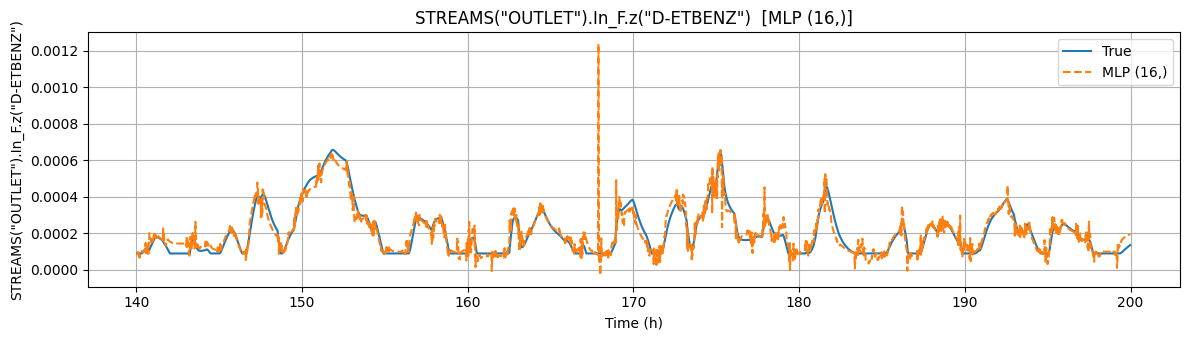

In [9]:
best = (results[results["model"] != "Mean (baseline)"]
        .sort_values("R2", ascending=False)
        .groupby("target").head(1).set_index("target")["model"])

for tgt in TARGETS:
    name = best[tgt]
    m, p = preds[(tgt, name)]
    plt.figure(figsize=(12, 3.5))
    plt.plot(test["Time"], test[tgt], label="True", lw=1.5)
    plt.plot(test["Time"], p, label=name, ls="--")
    plt.xlabel("Time (h)")
    plt.ylabel(tgt)
    plt.title(f"{tgt}  [{name}]")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

## 9. What drives the prediction

Random forest importances show which measurements the model relies on. Check that
they match the process: reactor temperature and the setpoints should matter most.

In [10]:
from sklearn.inspection import permutation_importance

best = (results[results["model"] != "Mean (baseline)"]
        .sort_values("R2", ascending=False)
        .groupby("target").head(1).set_index("target")["model"])

for tgt in TARGETS:
    name = best[tgt]
    m, _ = preds[(tgt, name)]
    if hasattr(m, "coef_"):
        score, label = pd.Series(np.ravel(m.coef_), index=keep), "coefficient"
    elif hasattr(m, "feature_importances_"):
        score, label = pd.Series(m.feature_importances_, index=keep), "importance"
    else:
        pi = permutation_importance(m, Xte_s, test[tgt].values, n_repeats=5, random_state=42)
        score, label = pd.Series(pi.importances_mean, index=keep), "permutation (drop in R2)"
    top = score.reindex(score.abs().sort_values(ascending=False).index).head(10)
    print(f"\n{tgt}  [{name}, {label}]")
    print(top.round(4).to_string())


STREAMS("OUTLET").In_F.z("ETBENZ")  [MLP (32, 16), permutation (drop in R2)]
TC.SP__lag1                       2.2318
BLOCKS("B1").Q                    2.2218
TC.SP                             2.0080
TC.SP__lag5                       0.6091
BLOCKS("B1").Q__lag1              0.5556
STREAMS("OUTLET").In_F.T__lag5    0.5360
TC.SP__lag10                      0.4126
TC.SP__lag20                      0.4083
BLOCKS("B1").T__lag5              0.3717
TC.SP__lag2                       0.3342

STREAMS("OUTLET").In_F.z("D-ETBENZ")  [MLP (16,), permutation (drop in R2)]
TC.SP__lag1                       42.8960
BLOCKS("B1").Q                    38.1990
TC.SP                             32.7332
BLOCKS("B1").T__lag5              16.2946
BLOCKS("B1").Q__lag1              12.6776
BLOCKS("B1").Q__lag2              10.9400
STREAMS("OUTLET").In_F.T__lag5     8.1105
BLOCKS("B1").T                     6.8513
STREAMS("ETHYLENE").F__lag2        5.8815
STREAMS("OUTLET").In_F.T__lag2     5.5604


## 10. Save the model for later use

In [11]:
best = (results[results["model"] != "Mean (baseline)"]
        .sort_values("R2", ascending=False)
        .groupby("target").head(1).set_index("target")["model"])

for tgt in TARGETS:
    name = best[tgt]
    m, _ = preds[(tgt, name)]
    r2 = float(results.loc[(results.target == tgt) & (results.model == name), "R2"].iloc[0])
    short = "ETBENZ" if "D-ETBENZ" not in tgt else "DETBENZ"
    joblib.dump({
        "model": m,
        "model_name": name,
        "scaler": scaler,
        "features": list(keep),
        "lags": LAGS,
        "target": tgt,
        "normal_band": BANDS,
        "sample_interval_h": DT_HOURS,
        "train_rows": len(train),
        "test_r2": r2,
    }, f"soft_sensor_{short}.joblib")
    print(f"saved {short}: {name}, test R2 = {r2:.3f}")

saved ETBENZ: MLP (32, 16), test R2 = 0.979
saved DETBENZ: MLP (16,), test R2 = 0.892
